# 02 · Reversible training: which integrator works?
A residual stack is an ODE integrator. If each block's *input* can be recomputed from its *output*,
activations need not be stored: backward rebuilds them layer by layer (custom `autograd.Function`
in `revllm.py`). We try three schemes, all with the same blocks/params (21.0M):

| variant | update | inverse | exact? |
|---|---|---|---|
| **euler** | $x_{n+1}=x_n+F_n(x_n)$ (= the baseline net) | fixed-point $x\leftarrow x_{n+1}-F_n(x)$ | only if Lip$(F_n)<1$ |
| **midpoint** (leapfrog) | $x_{n+1}=x_{n-1}+F_n(x_n)$ | $x_{n-1}=x_{n+1}-F_n(x_n)$ | yes |
| **revnet** (coupling / symplectic Euler) | $y_1=x_1+\mathrm{Attn}(x_2),\; y_2=x_2+\mathrm{MLP}(y_1)$ | $x_2=y_2-\mathrm{MLP}(y_1),\; x_1=y_1-\mathrm{Attn}(x_2)$ | yes |

Steps: (1) gradient check vs. plain autograd, (2) 5M-token bake-off at batch 32,
(3) full 50M-token run of the winner at the **same batch size as the baseline (32)**.

## 0. Setup
Runtime → Change runtime type → **GPU** (T4 is enough; L4/A100 are faster). Results and the tokenized data are cached on Google Drive (`USE_DRIVE=True`) so the notebooks can share them; set it to `False` to keep everything in `/content`.

In [1]:
import os, sys
USE_DRIVE = os.environ.get("REVLLM_USE_DRIVE", "1") == "1"   # persist data + results on Google Drive
SMOKE = os.environ.get("REVLLM_SMOKE", "0") == "1"   # True = tiny end-to-end pipeline check (~2 min)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/revllm-50m"
else:
    WORK = os.path.abspath("work")
os.makedirs(WORK, exist_ok=True)
DATA_DIR, RES_DIR = f"{WORK}/data", f"{WORK}/results"
print("work dir:", WORK)
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!pip -q install tokenizers datasets

work dir: /content/repo/work
name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07


In [2]:
%%writefile revllm.py
"""
revllm.py - a ~20M-parameter GPT trained on 50M tokens, with memory-free
(reversible) backpropagation through the transformer stack.

Stack modes (ModelConfig.mode):
  standard  : ordinary pre-LN transformer, x <- x + F(x), autograd stores every activation.
  euler     : SAME forward as `standard` (forward Euler step x_{n+1} = x_n + F(x_n)),
              but activations are NOT stored. In backward, x_n is recovered from x_{n+1}
              by fixed-point iteration  x <- x_{n+1} - F(x)  (approximate inverse).
  midpoint  : leapfrog / explicit-midpoint two-step scheme
              x_{n+1} = x_{n-1} + F_n(x_n)   (i.e. x_{n+1} = x_{n-1} + 2h f(x_n))
              exactly invertible: x_{n-1} = x_{n+1} - F_n(x_n).
  revnet    : RevNet / Reformer additive coupling (a symplectic-Euler / leapfrog split):
              y1 = x1 + Attn(x2);  y2 = x2 + MLP(y1)
              exactly invertible: x2 = y2 - MLP(y1);  x1 = y1 - Attn(x2).

In all three reversible modes only the output state of the whole stack is kept for
backward; each block's activations are rebuilt on the fly, so activation memory
no longer grows with depth.

Everything (data, tokenizer, model, reversible autograd, trainer, batch-size probe)
lives in this one file so each notebook can run standalone on Colab.
"""
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import json
import math
import time
from dataclasses import dataclass, asdict, field
from typing import Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

EOS = "<|endoftext|>"
_LOG = os.environ.get("REVLLM_LOG")     # optional: mirror progress lines to a file


def print(*a, **k):                      # flush always; tee to $REVLLM_LOG if set
    import builtins
    builtins.print(*a, **k, flush=True)
    if _LOG:
        with open(_LOG, "a") as f:
            f.write(" ".join(str(x) for x in a) + "\n")


# ----------------------------------------------------------------------------------
# Data: TinyStories -> byte-level BPE (8k vocab) -> uint16 token files
# ----------------------------------------------------------------------------------
def _iter_texts(source, split):
    """Yield raw documents. `source` = 'tinystories' (HF hub) or a local .txt path
    (documents separated by blank lines / EOS) for offline testing."""
    if source == "tinystories":
        from datasets import load_dataset
        ds = load_dataset("roneneldan/TinyStories", split=split, streaming=True)
        for ex in ds:
            t = ex["text"].strip()
            if t:
                yield t
    else:
        with open(source, "r", encoding="utf-8") as f:
            raw = f.read()
        docs = [d.strip() for d in raw.replace(EOS, "\n\n").split("\n\n") if d.strip()]
        if split != "train":           # tiny local val split
            docs = docs[: max(1, len(docs) // 20)]
        for d in docs:
            yield d


def train_tokenizer(source, vocab_size, n_docs, path):
    from tokenizers import Tokenizer, models, pre_tokenizers, decoders, trainers
    tok = Tokenizer(models.BPE())
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=[EOS],
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
                                  show_progress=False)

    def it():
        for i, t in enumerate(_iter_texts(source, "train")):
            if i >= n_docs:
                break
            yield t
    tok.train_from_iterator(it(), trainer=trainer)
    tok.save(path)
    return tok


def _encode_to_file(tok, source, split, n_tokens, path, batch_docs=4096):
    eos_id = tok.token_to_id(EOS)
    buf, out, count, t0 = [], [], 0, time.time()

    def flush():
        nonlocal count
        for enc in tok.encode_batch(buf):
            ids = enc.ids + [eos_id]
            out.append(np.asarray(ids, dtype=np.uint16))
            count += len(ids)
        buf.clear()

    for t in _iter_texts(source, split):
        buf.append(t)
        if len(buf) >= batch_docs:
            flush()
            if count >= n_tokens:
                break
    if buf and count < n_tokens:
        flush()
    arr = np.concatenate(out)[:n_tokens]
    arr.tofile(path)
    print(f"  {split}: {len(arr):,} tokens -> {path} ({time.time()-t0:.0f}s)")
    return len(arr)


def prepare_data(cache_dir="data", source="tinystories", vocab_size=8192,
                 n_train_tokens=51_000_000, n_val_tokens=1_000_000, tok_docs=100_000):
    """Idempotent. Returns dict(train=np.memmap, val=np.memmap, tokenizer=Tokenizer)."""
    from tokenizers import Tokenizer
    os.makedirs(cache_dir, exist_ok=True)
    tok_path = os.path.join(cache_dir, "tokenizer.json")
    tr_path, va_path = os.path.join(cache_dir, "train.bin"), os.path.join(cache_dir, "val.bin")
    if os.path.exists(tok_path):
        tok = Tokenizer.from_file(tok_path)
    else:
        t0 = time.time()
        tok = train_tokenizer(source, vocab_size, tok_docs, tok_path)
        print(f"  tokenizer trained ({tok.get_vocab_size()} tokens, {time.time()-t0:.0f}s)")
    need = lambda p, n: (not os.path.exists(p)) or os.path.getsize(p) // 2 < n
    if need(tr_path, n_train_tokens):
        _encode_to_file(tok, source, "train", n_train_tokens, tr_path)
    if need(va_path, min(n_val_tokens, 1)):
        _encode_to_file(tok, source, "validation", n_val_tokens, va_path)
    train = np.memmap(tr_path, dtype=np.uint16, mode="r")
    val = np.memmap(va_path, dtype=np.uint16, mode="r")
    print(f"data ready: train {len(train):,} tok | val {len(val):,} tok | vocab {tok.get_vocab_size()}")
    return dict(train=train, val=val, tokenizer=tok)


class Batcher:
    """Walks a random permutation of non-overlapping (T+1)-token windows: every training
    token is seen at most once, so `total_tokens` really is the number of tokens trained on."""
    def __init__(self, data, B, T, device, seed=0):
        self.data, self.B, self.T, self.device = data, B, T, device
        n = (len(data) - 1) // T
        self.starts = np.random.default_rng(seed).permutation(n) * T
        self.i = 0

    def next(self):
        if self.i + self.B > len(self.starts):
            self.i = 0
        s = self.starts[self.i:self.i + self.B]
        self.i += self.B
        idx = s[:, None] + np.arange(self.T + 1)[None, :]
        xy = torch.from_numpy(self.data[idx].astype(np.int64))
        if self.device.type == "cuda":
            xy = xy.pin_memory().to(self.device, non_blocking=True)
        return xy[:, :-1], xy[:, 1:]


# ----------------------------------------------------------------------------------
# Model
# ----------------------------------------------------------------------------------
@dataclass
class ModelConfig:
    vocab_size: int = 8192
    seq_len: int = 512
    d_model: int = 384
    n_layer: int = 10
    n_head: int = 6
    mlp_ratio: int = 4
    mode: str = "standard"      # standard | euler | midpoint | revnet
    euler_iters: int = 4        # fixed-point iterations for the approximate Euler inverse
    ce_chunk: int = 8192        # tokens per chunk in the (re-computed) LM-head + CE; 0 = off
    emb_std: float = 0.02       # init std of token/pos embeddings (sets residual-stream scale)


class Attn(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.ln = nn.LayerNorm(c.d_model)
        self.qkv = nn.Linear(c.d_model, 3 * c.d_model, bias=False)
        self.proj = nn.Linear(c.d_model, c.d_model, bias=False)
        self.h = c.n_head

    def forward(self, x):                      # returns the residual *update* only
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln(x)).split(C, dim=2)
        q, k, v = (t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(y.transpose(1, 2).reshape(B, T, C))


class MLP(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.ln = nn.LayerNorm(c.d_model)
        self.fc = nn.Linear(c.d_model, c.mlp_ratio * c.d_model, bias=False)
        self.proj = nn.Linear(c.mlp_ratio * c.d_model, c.d_model, bias=False)

    def forward(self, x):
        return self.proj(F.gelu(self.fc(self.ln(x)), approximate="tanh"))


class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.attn, self.mlp = Attn(c), MLP(c)

    def F(self, x):                            # full residual function: block(x) - x
        a = self.attn(x)
        return a + self.mlp(x + a)

    def forward(self, x):                      # standard pre-LN block
        x = x + self.attn(x)
        return x + self.mlp(x)


# ----------------------------------------------------------------------------------
# Reversible autograd: keep only the stack's output, rebuild activations in backward
# ----------------------------------------------------------------------------------
def _amp_state(x):
    dev = x.device.type
    return dev, torch.is_autocast_enabled(dev), torch.get_autocast_dtype(dev)


class RevTwoState(torch.autograd.Function):
    """Exactly-invertible two-state stacks: 'revnet' (coupling) and 'midpoint' (leapfrog)."""

    @staticmethod
    def forward(ctx, a, b, blocks, mode):
        for blk in blocks:                     # runs under no_grad -> nothing is stored
            if mode == "revnet":
                a = a + blk.attn(b)            # y1 = x1 + Attn(x2)
                b = b + blk.mlp(a)             # y2 = x2 + MLP(y1)
            else:                              # midpoint: (x_{n-1}, x_n) -> (x_n, x_{n-1} + F(x_n))
                a, b = b, a + blk.F(b)
        ctx.blocks, ctx.mode, ctx.amp = blocks, mode, _amp_state(a)
        ctx.save_for_backward(a, b)
        return a, b

    @staticmethod
    def backward(ctx, ga, gb):
        a, b = ctx.saved_tensors
        dev, amp_on, amp_dt = ctx.amp
        for blk in reversed(ctx.blocks):
            with torch.enable_grad(), torch.autocast(dev, dtype=amp_dt, enabled=amp_on):
                if ctx.mode == "revnet":       # a=y1, b=y2
                    y1 = a.detach().requires_grad_(True)
                    m = blk.mlp(y1)
                    x2 = (b - m.detach()).detach()                 # reconstruct x2
                    torch.autograd.backward(m, gb)                 # -> y1.grad, MLP params
                    g_y1 = ga + y1.grad
                    x2r = x2.requires_grad_(True)
                    at = blk.attn(x2r)
                    x1 = (a - at.detach()).detach()                # reconstruct x1
                    torch.autograd.backward(at, g_y1)              # -> x2.grad, Attn params
                    ga, gb = g_y1, gb + x2r.grad
                    a, b = x1, x2.detach()
                else:                          # midpoint: a=x_n, b=x_{n+1}
                    xn = a.detach().requires_grad_(True)
                    f = blk.F(xn)
                    x_prev = (b - f.detach()).detach()             # x_{n-1} = x_{n+1} - F(x_n)
                    torch.autograd.backward(f, gb)
                    ga, gb = gb, ga + xn.grad                      # grads wrt (x_{n-1}, x_n)
                    a, b = x_prev, xn.detach()
        return ga, gb, None, None


class RevEuler(torch.autograd.Function):
    """Forward Euler (the standard residual net) with an *approximate* inverse:
    x_n = x_{n+1} - F(x_n) solved by fixed-point iteration (converges if Lip(F) < 1)."""
    stats = {"recon_residual": float("nan")}
    track = True        # record the fixed-point residual (one host sync per layer)

    @staticmethod
    def forward(ctx, x, blocks, iters):
        for blk in blocks:
            x = x + blk.F(x)
        ctx.blocks, ctx.iters, ctx.amp = blocks, iters, _amp_state(x)
        ctx.save_for_backward(x)
        return x

    @staticmethod
    def backward(ctx, gy):
        (y,) = ctx.saved_tensors
        dev, amp_on, amp_dt = ctx.amp
        res = 0.0
        for blk in reversed(ctx.blocks):
            with torch.no_grad(), torch.autocast(dev, dtype=amp_dt, enabled=amp_on):
                x = y
                for k in range(ctx.iters):
                    x_new = y - blk.F(x)
                    if k == ctx.iters - 1 and RevEuler.track:   # last fixed-point step size
                        res = max(res, ((x_new - x).float().norm() / y.float().norm()).item())
                    x = x_new
            with torch.enable_grad(), torch.autocast(dev, dtype=amp_dt, enabled=amp_on):
                xr = x.detach().requires_grad_(True)
                out = xr + blk.F(xr)
                torch.autograd.backward(out, gy)
            gy, y = xr.grad, x.detach()
        RevEuler.stats["recon_residual"] = res
        return gy, None, None


# ----------------------------------------------------------------------------------
def _ce_sum(h, w, t):
    return F.cross_entropy(F.linear(h, w).float(), t, reduction="sum")


class GPT(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.c = c
        self.tok = nn.Embedding(c.vocab_size, c.d_model)
        self.pos = nn.Embedding(c.seq_len, c.d_model)
        self.blocks = nn.ModuleList([Block(c) for _ in range(c.n_layer)])
        self.ln_f = nn.LayerNorm(c.d_model)
        self.apply(self._init)
        nn.init.normal_(self.tok.weight, 0.0, c.emb_std)
        nn.init.normal_(self.pos.weight, 0.0, c.emb_std)
        for n, p in self.named_parameters():
            if n.endswith("proj.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * c.n_layer))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def n_params(self, non_embedding=False):
        n = sum(p.numel() for p in self.parameters())
        return n - (self.tok.weight.numel() + self.pos.weight.numel()) if non_embedding else n

    # -- the transformer stack, in every mode; reference=True uses plain autograd -------
    def stack(self, x, reference=False):
        c, blocks = self.c, self.blocks
        if c.mode == "standard":
            for blk in blocks:
                x = blk(x)
            return x
        if c.mode == "euler":
            if reference or not torch.is_grad_enabled():
                for blk in blocks:
                    x = x + blk.F(x)
                return x
            return RevEuler.apply(x, blocks, c.euler_iters)
        if reference or not torch.is_grad_enabled():
            a, b = x, x
            for blk in blocks:
                if c.mode == "revnet":
                    a = a + blk.attn(b)
                    b = b + blk.mlp(a)
                else:
                    a, b = b, a + blk.F(b)
        else:
            a, b = RevTwoState.apply(x, x, blocks, c.mode)
        return 0.5 * (a + b) if c.mode == "revnet" else b

    def forward(self, idx, targets=None, reference=False):
        B, T = idx.shape
        x = self.tok(idx) + self.pos(torch.arange(T, device=idx.device))
        h = self.ln_f(self.stack(x, reference))
        w = self.tok.weight                                          # tied LM head
        if targets is None:
            return F.linear(h[:, -1:], w).float()
        h2, t = h.reshape(-1, h.size(-1)), targets.reshape(-1)
        N, ch = t.numel(), self.c.ce_chunk
        if not torch.is_grad_enabled():                              # eval: chunk, no recompute
            k = ch if ch > 0 else 8192
            return sum(_ce_sum(h2[i:i+k], w, t[i:i+k]) for i in range(0, N, k)) / N
        if ch <= 0 or N <= ch:
            return _ce_sum(h2, w, t) / N
        # LM-head + CE in chunks, logits recomputed in backward (never all materialised)
        tot = 0.0
        for i in range(0, N, ch):
            tot = tot + checkpoint(_ce_sum, h2[i:i+ch], w, t[i:i+ch], use_reentrant=False)
        return tot / N

    @torch.no_grad()
    def generate(self, idx, n_new, temperature=0.8, top_k=40):
        for _ in range(n_new):
            logits = self(idx[:, -self.c.seq_len:])[:, -1] / temperature
            v, _ = torch.topk(logits, top_k)
            logits[logits < v[:, [-1]]] = -float("inf")
            idx = torch.cat([idx, torch.multinomial(F.softmax(logits, -1), 1)], 1)
        return idx


# ----------------------------------------------------------------------------------
# Diagnostics
# ----------------------------------------------------------------------------------
def grad_check(mode, device="cpu", euler_iters=4, seed=0, d=128, L=4, T=64, B=4, V=512,
               dtype=torch.float64, emb_std=0.02, branch_scale=4.0):
    """Compare reversible gradients against plain autograd on the same forward.
    Returns max relative error and cosine similarity over all parameter grads."""
    torch.manual_seed(seed)
    c = ModelConfig(vocab_size=V, seq_len=T, d_model=d, n_layer=L, n_head=4, mode=mode,
                    euler_iters=euler_iters, ce_chunk=0, emb_std=emb_std)
    m = GPT(c).to(device, dtype)
    # larger-than-init residual branches make the check meaningful (not ~identity)
    with torch.no_grad():
        for n, p in m.named_parameters():
            if n.endswith("proj.weight"):
                p.mul_(branch_scale)
    idx = torch.randint(0, V, (B, T), device=device)
    tgt = torch.randint(0, V, (B, T), device=device)
    ref_mode = "standard" if mode == "euler" else mode
    grads = {}
    for ref in (True, False):
        m.zero_grad(set_to_none=True)
        m.c.mode = ref_mode if ref else mode
        loss = m(idx, tgt, reference=ref)
        loss.backward()
        grads[ref] = torch.cat([p.grad.flatten() for p in m.parameters()])
    m.c.mode = mode
    g0, g1 = grads[True], grads[False]
    rel = ((g1 - g0).norm() / g0.norm()).item()
    cos = F.cosine_similarity(g0, g1, dim=0).item()
    return dict(mode=mode, euler_iters=euler_iters if mode == "euler" else None, emb_std=emb_std,
                rel_err=rel, cosine=cos, loss=loss.item(),
                euler_fixed_point_residual=RevEuler.stats["recon_residual"] if mode == "euler" else None)


def saved_activation_bytes(model, idx, tgt):
    """Bytes of tensors autograd saves for backward (activation memory), device-agnostic.
    Parameters are excluded."""
    params = {p.data_ptr() for p in model.parameters()}
    seen, total = set(), [0]

    def pack(t):
        if t.data_ptr() not in params and t.data_ptr() not in seen:
            seen.add(t.data_ptr())
            total[0] += t.numel() * t.element_size()
        return t
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        loss = model(idx, tgt)
    loss.backward()
    model.zero_grad(set_to_none=True)
    return total[0]


# ----------------------------------------------------------------------------------
# Training
# ----------------------------------------------------------------------------------
@dataclass
class TrainConfig:
    run_name: str = "baseline"
    batch_size: int = 32
    total_tokens: int = 50_000_000
    lr: float = 1e-3
    min_lr_frac: float = 0.1
    warmup_frac: float = 0.05
    min_warmup: int = 10
    weight_decay: float = 0.1
    grad_clip: float = 1.0
    eval_every_tokens: int = 5_000_000
    eval_batches: int = 16
    final_eval_tokens: int = 500_000
    log_every: int = 10
    seed: int = 1337
    dtype: str = "auto"          # auto | bf16 | fp16 | fp32
    max_steps: Optional[int] = None   # smoke tests only
    out_dir: str = "results"
    sample_prompt: str = "Once upon a time"


def pick_dtype(name, device):
    if device.type != "cuda":
        return torch.float32 if name in ("auto", "fp32") else {"bf16": torch.bfloat16}.get(name, torch.float32)
    if name == "auto":
        return torch.bfloat16 if torch.cuda.is_bf16_supported() and \
            torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    return {"bf16": torch.bfloat16, "fp16": torch.float16, "fp32": torch.float32}[name]


def make_optimizer(model, lr, wd, device):
    decay = [p for n, p in model.named_parameters() if p.dim() >= 2]
    no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]
    kw = dict(fused=True) if device.type == "cuda" else {}
    return torch.optim.AdamW([{"params": decay, "weight_decay": wd},
                              {"params": no_decay, "weight_decay": 0.0}],
                             lr=lr, betas=(0.9, 0.95), eps=1e-8, **kw)


def gpu_info():
    if not torch.cuda.is_available():
        return dict(device="cpu", torch=torch.__version__)
    p = torch.cuda.get_device_properties(0)
    return dict(device=p.name, total_mem_gb=round(p.total_memory / 2**30, 2),
                torch=torch.__version__, capability=list(torch.cuda.get_device_capability()))


@torch.no_grad()
def evaluate(model, data, B, T, device, amp_dtype, n_tokens=None, n_batches=None, seed=123):
    model.eval()
    n_batches = n_batches or max(1, math.ceil(n_tokens / (B * T)))
    bt = Batcher(data, B, T, device, seed=seed)
    tot = 0.0
    for _ in range(n_batches):
        x, y = bt.next()
        with torch.autocast(device.type, dtype=amp_dtype, enabled=amp_dtype != torch.float32):
            tot += model(x, y).item()
    model.train()
    return tot / n_batches


def train(mcfg: ModelConfig, tcfg: TrainConfig, data, device=None, verbose=True):
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(tcfg.seed)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    amp_dtype = pick_dtype(tcfg.dtype, device)
    use_amp = amp_dtype != torch.float32
    is_cuda = device.type == "cuda"
    if is_cuda:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    model = GPT(mcfg).to(device)
    opt = make_optimizer(model, tcfg.lr, tcfg.weight_decay, device)
    scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16 and is_cuda))
    B, T = tcfg.batch_size, mcfg.seq_len
    tok_per_step = B * T
    steps = math.ceil(tcfg.total_tokens / tok_per_step)
    if tcfg.max_steps:
        steps = min(steps, tcfg.max_steps)
    warmup = max(tcfg.min_warmup, int(tcfg.warmup_frac * steps))
    warmup = min(warmup, max(1, steps // 2))

    def lr_at(s):
        if s < warmup:
            return tcfg.lr * (s + 1) / warmup
        p = (s - warmup) / max(1, steps - warmup)
        return tcfg.lr * (tcfg.min_lr_frac + (1 - tcfg.min_lr_frac) * 0.5 * (1 + math.cos(math.pi * p)))

    bt = Batcher(data["train"], B, T, device, seed=tcfg.seed)
    eval_B = min(B, 64)
    eval_every = max(1, round(tcfg.eval_every_tokens / tok_per_step))
    hist = dict(step=[], tokens=[], loss=[], lr=[], tok_s=[], val_step=[], val_tokens=[], val_loss=[])
    if verbose:
        print(f"[{tcfg.run_name}] mode={mcfg.mode} params={model.n_params()/1e6:.2f}M "
              f"B={B} T={T} tok/step={tok_per_step:,} steps={steps} warmup={warmup} "
              f"lr={tcfg.lr:.2e} amp={amp_dtype}")

    static_mem, train_time, t_log, tok_log = None, 0.0, None, 0
    loss_window, nonfinite = [], 0
    steady_tok, steady_time = 0, 0.0
    t_start = time.time()
    for s in range(steps):
        if is_cuda:
            torch.cuda.synchronize()
        t0 = time.time()
        for g in opt.param_groups:
            g["lr"] = lr_at(s)
        x, y = bt.next()
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            loss = model(x, y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), tcfg.grad_clip)
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)
        if is_cuda:
            torch.cuda.synchronize()
        dt = time.time() - t0
        train_time += dt
        if s >= 5:                                 # skip warm-up / allocator settling steps
            steady_tok += tok_per_step
            steady_time += dt
        if static_mem is None and is_cuda:
            static_mem = torch.cuda.memory_allocated()   # params + grads(None) + Adam states
        lv = loss.item()
        if not math.isfinite(lv):
            nonfinite += 1
        loss_window.append(lv)
        if s % tcfg.log_every == 0 or s == steps - 1:
            ts = tok_per_step / dt
            hist["step"].append(s); hist["tokens"].append((s + 1) * tok_per_step)
            hist["loss"].append(lv); hist["lr"].append(lr_at(s)); hist["tok_s"].append(ts)
            if verbose:
                mem = torch.cuda.max_memory_allocated() / 2**30 if is_cuda else 0
                extra = f" recon={RevEuler.stats['recon_residual']:.1e}" if mcfg.mode == "euler" else ""
                print(f"  step {s:5d}/{steps} loss {lv:.4f} gnorm {gn:.2f} lr {lr_at(s):.2e} "
                      f"{ts/1e3:7.1f}k tok/s peak {mem:.2f}GB{extra}")
        if nonfinite > 20:
            print("  !! loss diverged (non-finite), stopping")
            break
        if (s + 1) % eval_every == 0 and s != steps - 1:
            vl = evaluate(model, data["val"], eval_B, T, device, amp_dtype, n_batches=tcfg.eval_batches)
            hist["val_step"].append(s); hist["val_tokens"].append((s + 1) * tok_per_step)
            hist["val_loss"].append(vl)
            if verbose:
                print(f"  -- val loss {vl:.4f} @ {(s+1)*tok_per_step/1e6:.1f}M tokens")

    wall = time.time() - t_start
    final_val = evaluate(model, data["val"], eval_B, T, device, amp_dtype, n_tokens=tcfg.final_eval_tokens)
    hist["val_step"].append(steps - 1); hist["val_tokens"].append(steps * tok_per_step)
    hist["val_loss"].append(final_val)
    peak_alloc = torch.cuda.max_memory_allocated() / 2**30 if is_cuda else None
    peak_res = torch.cuda.max_memory_reserved() / 2**30 if is_cuda else None
    sample = ""
    if "tokenizer" in data and data["tokenizer"] is not None:
        tok = data["tokenizer"]
        ids = torch.tensor([tok.encode(tcfg.sample_prompt).ids], device=device)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            out = model.generate(ids, 120)
        sample = tok.decode(out[0].tolist())
    tail = [l for l in loss_window[-50:] if math.isfinite(l)]
    res = dict(
        run_name=tcfg.run_name, model=asdict(mcfg), train=asdict(tcfg), hw=gpu_info(),
        amp_dtype=str(amp_dtype), n_params=model.n_params(),
        n_params_non_embedding=model.n_params(non_embedding=True),
        steps=len(loss_window), tokens_trained=len(loss_window) * tok_per_step,
        tokens_per_step=tok_per_step, warmup_steps=warmup,
        final_train_loss=float(np.mean(tail)) if tail else float("nan"),
        final_val_loss=final_val, diverged=nonfinite > 20,
        tokens_per_sec=steady_tok / steady_time if steady_time else tok_per_step * len(loss_window) / train_time,
        train_time_s=train_time, wall_time_s=wall,
        peak_mem_alloc_gb=peak_alloc, peak_mem_reserved_gb=peak_res,
        static_mem_gb=static_mem / 2**30 if static_mem else None,
        activation_mem_gb=(peak_alloc - static_mem / 2**30) if (peak_alloc and static_mem) else None,
        euler_recon_residual=RevEuler.stats["recon_residual"] if mcfg.mode == "euler" else None,
        sample=sample, history=hist,
    )
    if verbose:
        print(f"[{tcfg.run_name}] DONE  train_loss {res['final_train_loss']:.4f}  val_loss {final_val:.4f}  "
              f"{res['tokens_per_sec']/1e3:.1f}k tok/s  peak {peak_alloc or 0:.2f}GB  "
              f"time {train_time/60:.1f} min")
    os.makedirs(tcfg.out_dir, exist_ok=True)
    with open(os.path.join(tcfg.out_dir, f"{tcfg.run_name}.json"), "w") as f:
        json.dump(res, f, indent=1)
    del model, opt
    if is_cuda:
        torch.cuda.empty_cache()
    return res


# ----------------------------------------------------------------------------------
# Max-batch probe
# ----------------------------------------------------------------------------------
def _try_batch(model, opt, scaler, B, T, V, device, amp_dtype):
    loss = x = None
    try:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        x = torch.randint(0, V, (B, T), device=device)
        with torch.autocast("cuda", dtype=amp_dtype, enabled=amp_dtype != torch.float32):
            loss = model(x, x)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)
        torch.cuda.synchronize()
        return True, torch.cuda.max_memory_allocated() / 2**30
    except torch.cuda.OutOfMemoryError:
        opt.zero_grad(set_to_none=True)
        return False, None
    finally:
        loss = x = None
        torch.cuda.empty_cache()


def probe_max_batch(mcfg: ModelConfig, dtype="auto", start=8, limit=4096, granularity=8, verbose=True):
    """Largest batch (sequences of length seq_len) whose fwd+bwd+AdamW step fits on the GPU.
    Doubling search, then bisection to `granularity`."""
    device = torch.device("cuda")
    amp_dtype = pick_dtype(dtype, device)
    model = GPT(mcfg).to(device)
    opt = make_optimizer(model, 1e-4, 0.1, device)
    scaler = torch.amp.GradScaler("cuda", enabled=amp_dtype == torch.float16)
    T, V = mcfg.seq_len, mcfg.vocab_size
    trace, ok_B, bad_B, B = [], 0, None, start
    while B <= limit:
        ok, mem = _try_batch(model, opt, scaler, B, T, V, device, amp_dtype)
        trace.append(dict(batch=B, ok=ok, peak_gb=mem))
        if verbose:
            print(f"  B={B:5d}  {'ok ' if ok else 'OOM'}  {'' if mem is None else f'{mem:.2f} GB'}")
        if not ok:
            bad_B = B
            break
        ok_B, B = B, B * 2
    if bad_B is not None:
        lo, hi = ok_B, bad_B
        while hi - lo > granularity:
            mid = (lo + hi) // 2 // granularity * granularity
            if mid <= lo:
                break
            ok, mem = _try_batch(model, opt, scaler, mid, T, V, device, amp_dtype)
            trace.append(dict(batch=mid, ok=ok, peak_gb=mem))
            if verbose:
                print(f"  B={mid:5d}  {'ok ' if ok else 'OOM'}  {'' if mem is None else f'{mem:.2f} GB'}")
            lo, hi = (mid, hi) if ok else (lo, mid)
        ok_B = lo
    del model, opt
    torch.cuda.empty_cache()
    oks = sorted([t for t in trace if t["ok"]], key=lambda t: t["batch"])
    slope = None
    if len(oks) >= 2:                             # GB per extra sequence (activation memory)
        slope = (oks[-1]["peak_gb"] - oks[0]["peak_gb"]) / (oks[-1]["batch"] - oks[0]["batch"])
    res = dict(mode=mcfg.mode, max_batch=ok_B, max_tokens_per_step=ok_B * T,
               hit_limit=bad_B is None, gb_per_sequence=slope, trace=trace, hw=gpu_info())
    if verbose:
        print(f"  => max batch for mode={mcfg.mode}: {ok_B} sequences ({ok_B*T:,} tokens/step)"
              + (f", {slope*1024:.1f} MB/sequence" if slope else ""))
    return res


def save_json(obj, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=1)


Overwriting revllm.py


In [3]:
import importlib, json, math, torch
import revllm as R; importlib.reload(R)
import matplotlib.pyplot as plt
print(torch.__version__, R.gpu_info())

TOTAL_TOKENS = 50_000_000 if not SMOKE else 400_000
DATA_SOURCE = os.environ.get("REVLLM_SOURCE", "tinystories")   # or a local .txt for offline tests
data = R.prepare_data(DATA_DIR, source=DATA_SOURCE, vocab_size=8192,
                      n_train_tokens=51_000_000 if not SMOKE else 1_000_000,
                      n_val_tokens=1_000_000 if not SMOKE else 100_000)
BASE_KW = dict(vocab_size=data["tokenizer"].get_vocab_size())
if SMOKE:                          # tiny model so the smoke test also runs on CPU
    BASE_KW.update(d_model=128, n_layer=4, n_head=4, seq_len=128)
M = lambda **kw: R.ModelConfig(**{**BASE_KW, **kw})   # d=384, 10 layers, 6 heads, T=512, vocab 8192
print(M())
print("params:", f"{R.GPT(M()).n_params()/1e6:.2f}M",
      "| non-embedding:", f"{R.GPT(M()).n_params(non_embedding=True)/1e6:.2f}M")
HAS_GPU = torch.cuda.is_available()

2.11.0+cu128 {'device': 'Tesla T4', 'total_mem_gb': 14.56, 'torch': '2.11.0+cu128', 'capability': [7, 5]}
data ready: train 51,000,000 tok | val 1,000,000 tok | vocab 8192


ModelConfig(vocab_size=8192, seq_len=512, d_model=384, n_layer=10, n_head=6, mlp_ratio=4, mode='standard', euler_iters=4, ce_chunk=8192, emb_std=0.02)


params: 21.05M | non-embedding: 17.71M


## 1. Gradient check (float64, small model) — are the reversible gradients right?

In [4]:
import pandas as pd
dev = "cuda" if torch.cuda.is_available() else "cpu"
rows = [R.grad_check(m, device=dev) for m in ["revnet", "midpoint"]]
for e in [0.02, 0.1, 0.5]:                      # Euler: inverse only converges if the residual
    for k in [1, 4, 8]:                          # stream is large relative to F's Lipschitz const.
        rows.append(R.grad_check("euler", device=dev, euler_iters=k, emb_std=e))
gc = pd.DataFrame(rows); R.save_json(rows, f"{RES_DIR}/grad_check.json"); gc

,mode,euler_iters,emb_std,rel_err,cosine,loss,euler_fixed_point_residual
0,revnet,NaN,0.02,3.108274e-15,1.000000,6.258132,NaN
1,midpoint,NaN,0.02,1.711445e-15,1.000000,6.289799,NaN
2,euler,1.0,0.02,9.432687e-01,0.511141,6.275150,6.741338e-01
3,euler,4.0,0.02,9.636973e-01,0.544072,6.275150,6.066369e-01
4,euler,8.0,0.02,9.839569e-01,0.532916,6.275150,9.545622e-01
5,euler,1.0,0.10,4.699962e-01,0.893283,7.349483,4.661697e-01
6,euler,4.0,0.10,1.484309e-01,0.989100,7.349483,1.285986e-01
7,euler,8.0,0.10,5.570149e-02,0.998454,7.349483,6.890447e-02
8,euler,1.0,0.50,2.039244e-02,0.999792,43.633156,1.103952e-01
9,euler,4.0,0.50,5.691696e-05,1.000000,43.633156,2.243721e-04


## 2. Bake-off: 5M tokens each, batch 32

In [5]:
def plot_runs(runs, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for r in runs:
        h = r["history"]
        ax[0].plot([t/1e6 for t in h["tokens"]], h["loss"], label=r["run_name"], alpha=.8)
        ax[1].plot([t/1e6 for t in h["val_tokens"]], h["val_loss"], "o-", label=r["run_name"])
    for a, t in zip(ax, ["train loss", "val loss"]):
        a.set_xlabel("tokens (M)"); a.set_ylabel(t); a.grid(alpha=.3); a.legend()
    ax[0].set_ylim(top=min(6, ax[0].get_ylim()[1]))
    fig.suptitle(title); plt.tight_layout(); plt.show()

def show(r):
    keys = ["run_name", "steps", "tokens_trained", "final_train_loss", "final_val_loss",
            "tokens_per_sec", "peak_mem_alloc_gb", "peak_mem_reserved_gb", "activation_mem_gb", "train_time_s"]
    for k in keys:
        v = r.get(k)
        print(f"  {k:22s} {v:,.4f}" if isinstance(v, float) else f"  {k:22s} {v}")
    print("  sample:", r["sample"][:400])

[02_bake_standard] mode=standard params=21.05M B=32 T=512 tok/step=16,384 steps=306 warmup=15 lr=1.00e-03 amp=torch.float16


  step     0/306 loss 9.0746 gnorm 11.37 lr 6.67e-05    48.0k tok/s peak 3.08GB


  step    50/306 loss 4.5890 gnorm 0.57 lr 9.68e-04    76.6k tok/s peak 3.24GB


  step   100/306 loss 4.0304 gnorm 0.42 lr 8.23e-04    75.4k tok/s peak 3.24GB


  step   150/306 loss 3.9509 gnorm 0.51 lr 6.01e-04    75.2k tok/s peak 3.24GB


...

  step   200/306 loss 3.9741 gnorm 0.55 lr 3.64e-04    61.4k tok/s peak 1.14GB


  step   250/306 loss 4.0221 gnorm 0.50 lr 1.80e-04    61.4k tok/s peak 1.14GB


  step   300/306 loss 3.8619 gnorm 0.51 lr 1.01e-04    61.2k tok/s peak 1.14GB


  step   305/306 loss 3.8910 gnorm 0.48 lr 1.00e-04    61.5k tok/s peak 1.14GB


[02_bake_revnet] DONE  train_loss 3.8835  val_loss 3.9078  61.5k tok/s  peak 1.14GB  time 1.4 min


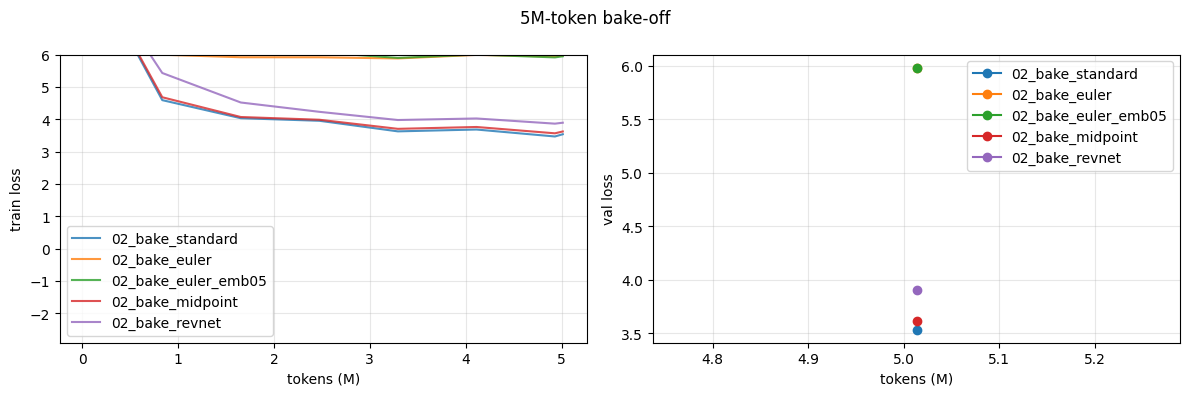

,variant,val_loss,train_loss,tok/s,peak GB,act GB,diverged,euler residual
0,standard (ref),3.533276,3.506210,76270,3.237898,2.986577,False,NaN
1,euler (4 it),5.981690,5.954333,33847,1.089461,0.838140,False,0.110432
2,"euler (4 it, emb .5)",5.981435,5.929412,34152,1.089461,0.838140,False,0.072790
3,midpoint,3.616514,3.591440,60670,1.112898,0.861577,False,NaN
4,revnet,3.907826,3.883458,61527,1.136336,0.885015,False,NaN


In [6]:
BATCH, BAKE_TOKENS = 32, (5_000_000 if not SMOKE else 200_000)
variants = {
    "standard (ref)":        M(mode="standard"),
    "euler (4 it)":          M(mode="euler", euler_iters=4),
    "euler (4 it, emb .5)":  M(mode="euler", euler_iters=4, emb_std=0.5),
    "midpoint":              M(mode="midpoint"),
    "revnet":                M(mode="revnet"),
}
bake = {}
for name, mc in variants.items():
    tag = "02_bake_" + name.split()[0] + ("_emb05" if "emb" in name else "")
    bake[name] = R.train(mc, R.TrainConfig(run_name=tag, batch_size=BATCH, total_tokens=BAKE_TOKENS,
                          lr=1e-3, eval_every_tokens=10**9, out_dir=RES_DIR,
                          log_every=50 if not SMOKE else 5), data)
tbl = pd.DataFrame([{ "variant": k, "val_loss": r["final_val_loss"], "train_loss": r["final_train_loss"],
    "tok/s": round(r["tokens_per_sec"]), "peak GB": r["peak_mem_alloc_gb"],
    "act GB": r["activation_mem_gb"], "diverged": r["diverged"],
    "euler residual": r["euler_recon_residual"]} for k, r in bake.items()])
plot_runs(list(bake.values()), "5M-token bake-off"); tbl

In [7]:
# pick the reversible variant with the lowest validation loss
rev = {k: r for k, r in bake.items() if not k.startswith("standard") and not r["diverged"]}
best_name = min(rev, key=lambda k: rev[k]["final_val_loss"])
BEST = variants[best_name]
print("chosen variant:", best_name, BEST)
R.save_json({"name": best_name, "model": R.asdict(BEST), "bakeoff": tbl.to_dict("records")},
            f"{RES_DIR}/chosen_variant.json")

chosen variant: midpoint ModelConfig(vocab_size=8192, seq_len=512, d_model=384, n_layer=10, n_head=6, mlp_ratio=4, mode='midpoint', euler_iters=4, ce_chunk=8192, emb_std=0.02)


## 3. Full run: chosen reversible variant, 50M tokens, batch 32 (same as baseline)

[02_reversible_b32] mode=midpoint params=21.05M B=32 T=512 tok/step=16,384 steps=3052 warmup=152 lr=1.00e-03 amp=torch.float16


  step     0/3052 loss 9.0875 gnorm 12.00 lr 6.58e-06    62.5k tok/s peak 0.96GB


  step    50/3052 loss 5.1042 gnorm 1.01 lr 3.36e-04    60.8k tok/s peak 1.11GB


  step   100/3052 loss 4.0961 gnorm 0.72 lr 6.64e-04    60.4k tok/s peak 1.11GB


  step   150/3052 loss 3.9374 gnorm 0.63 lr 9.93e-04    60.3k tok/s peak 1.11GB


...

  -- val loss 1.8709 @ 50.0M tokens


  step  3050/3052 loss 1.7761 gnorm 0.49 lr 1.00e-04    60.8k tok/s peak 1.11GB


  step  3051/3052 loss 1.7641 gnorm 0.49 lr 1.00e-04    60.6k tok/s peak 1.11GB


[02_reversible_b32] DONE  train_loss 1.8126  val_loss 1.8712  60.5k tok/s  peak 1.11GB  time 13.8 min


  run_name               02_reversible_b32
  steps                  3052
  tokens_trained         50003968
  final_train_loss       1.8126
  final_val_loss         1.8712
  tokens_per_sec         60,537.4406
  peak_mem_alloc_gb      1.1129
  peak_mem_reserved_gb   1.3008
  activation_mem_gb      0.8616
  train_time_s           825.9903
  sample: Once upon a time, there was a little girl named Lily. She loved to play with her dolls and teddy bears. One day, Lily's mommy asked her to help clean up her room. 

Lily was happy to help. She cleaned up her room and put the toys away. While they were cleaning, Lily's mommy asked her to help clean up her toys. 

Lily was happy to help and helped clean up her dolls. She got cleaned and cleaned up t


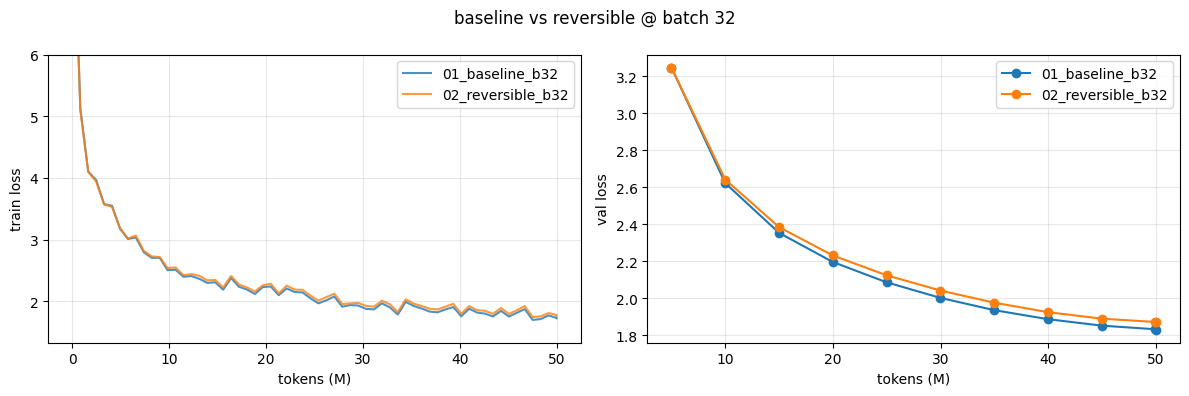

In [8]:
rev_run = R.train(BEST, R.TrainConfig(run_name="02_reversible_b32", batch_size=BATCH,
                  total_tokens=TOTAL_TOKENS, lr=1e-3, out_dir=RES_DIR,
                  log_every=50 if not SMOKE else 5), data)
show(rev_run)
runs = [rev_run]
if os.path.exists(f"{RES_DIR}/01_baseline_b32.json"):
    runs.insert(0, json.load(open(f"{RES_DIR}/01_baseline_b32.json")))
plot_runs(runs, "baseline vs reversible @ batch 32")